# GemmaForge probe vs baselines

A probe with AUC=0.9 is only impressive if it beats *trivial* baselines.
This notebook ranks the probe against:

- `random`  -> floor (AUC≈0.5)
- `length`  -> normalised code length. If this gets AUC>0.7 there's a
               length artifact in the dataset, and the probe inherits
               some of its "win" from that artifact.
- `regex`   -> Semgrep-style pattern count using the same patterns as
               `scripts/eval_lora.py`.

**What this notebook is for**: making sure the writeup never reports
"the probe gets 0.X" without also reporting "and a regex gets 0.Y on
the same slice." That comparison can be unflattering — that's the point.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "src" / "eval").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

from src.eval import probe_io
from src.eval.splits import make_splits
from src.eval.probe_io import fit_logreg_on_split
from src.eval.baselines import RegexBaseline, LengthBaseline, RandomBaseline

LAYER = 17
X, y = probe_io.load_activations(ROOT / f"data/activations_v2/activations_layer{LAYER:02d}.npz")
rows = probe_io.load_pairs(ROOT / "data/pairs.jsonl")
splits = make_splits(rows, y)
baselines = [RandomBaseline(), LengthBaseline(), RegexBaseline()]

## AUC comparison table

In [2]:
table_rows = []
for sp in splits:
    if len(np.unique(y[sp.train_idx])) < 2 or len(np.unique(y[sp.test_idx])) < 2:
        continue
    probe = fit_logreg_on_split(X, y, sp.train_idx)
    probe_probs = probe.score(X[sp.test_idx])
    probe_auc = roc_auc_score(y[sp.test_idx], probe_probs)

    bl_aucs = {}
    rows_te = [rows[i] for i in sp.test_idx.tolist()]
    for bl in baselines:
        bl_probs = bl.score(rows_te)
        bl_aucs[bl.name] = roc_auc_score(y[sp.test_idx], bl_probs)

    table_rows.append({
        "split": sp.name,
        "probe": probe_auc,
        **bl_aucs,
    })

# Pretty print.
headers = ["split", "probe", "random", "length", "regex"]
print("| " + " | ".join(headers) + " |")
print("|" + "|".join("---" for _ in headers) + "|")
for r in table_rows:
    cells = [f"`{r['split']}`"] + [f"{r[h]:.3f}" for h in headers[1:]]
    # Bold the winner.
    aucs = [r[h] for h in headers[1:]]
    winner_idx = int(np.argmax(aucs))
    cells[1 + winner_idx] = f"**{cells[1 + winner_idx]}**"
    print("| " + " | ".join(cells) + " |")

| split | probe | random | length | regex |
|---|---|---|---|---|
| `random_stratified` | **0.963** | 0.393 | 0.895 | 0.701 |
| `group_repo` | **0.958** | 0.508 | 0.911 | 0.685 |
| `heldout_cwe::CWE-78` | **0.923** | 0.520 | 0.840 | 0.721 |
| `heldout_cwe::CWE-338` | **0.923** | 0.474 | 0.885 | 0.782 |
| `heldout_cwe::CWE-95` | **0.942** | 0.446 | 0.884 | 0.675 |
| `heldout_cwe::CWE-94` | **0.960** | 0.476 | 0.935 | 0.748 |
| `heldout_cwe::CWE-328` | 0.944 | 0.473 | 0.904 | **0.991** |
| `heldout_lang::test=javascript` | **0.907** | 0.522 | 0.883 | 0.647 |
| `heldout_lang::test=python` | **0.929** | 0.519 | 0.885 | 0.719 |


## Visual comparison

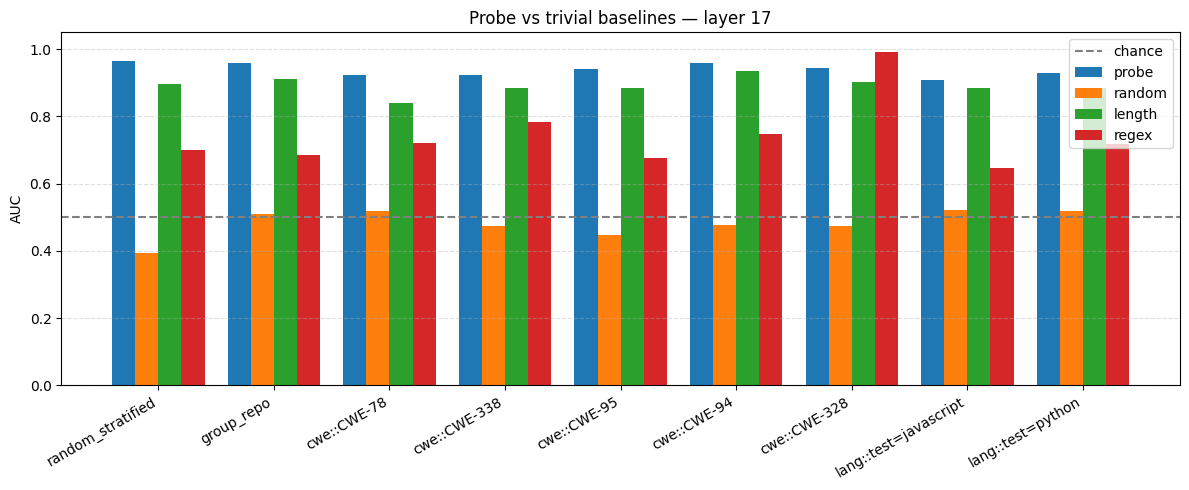

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
x_pos = np.arange(len(table_rows))
width = 0.2
for i, h in enumerate(["probe", "random", "length", "regex"]):
    vals = [r[h] for r in table_rows]
    ax.bar(x_pos + i * width, vals, width, label=h)
ax.set_xticks(x_pos + 1.5 * width)
ax.set_xticklabels([r["split"].replace("heldout_", "") for r in table_rows], rotation=30, ha="right")
ax.axhline(0.5, color="gray", linestyle="--", label="chance")
ax.set_ylim(0, 1.05)
ax.set_ylabel("AUC")
ax.set_title(f"Probe vs trivial baselines — layer {LAYER}")
ax.legend()
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## ROC overlay on the worst-credible split

Putting the probe and the regex on the same ROC plot makes the gap (or
lack of gap) at low FPR plain. The streaming UI cares about low FPR
— at FPR=0.05 we get one false alarm per ~20 tokens of safe code.

worst credible split = heldout_lang::test=javascript


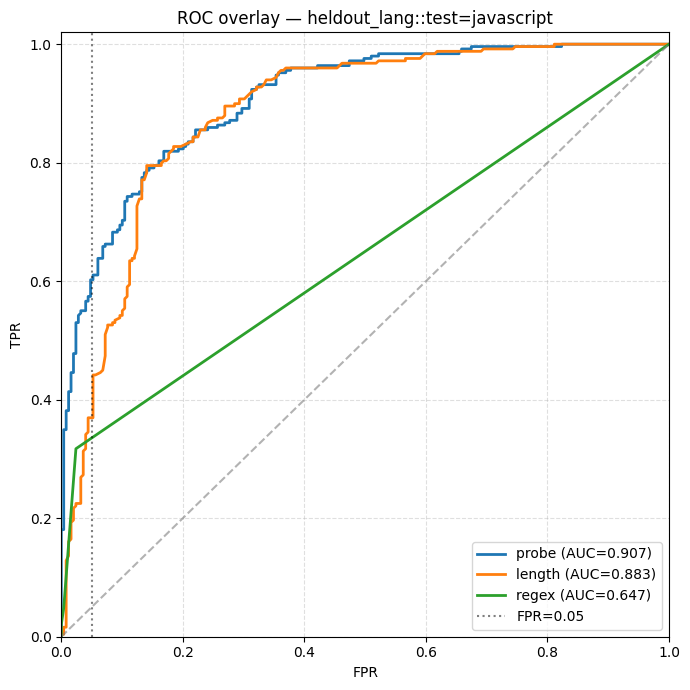

In [4]:
worst = min((r for r in table_rows if r["split"].startswith("heldout_lang")), key=lambda r: r["probe"])
print(f"worst credible split = {worst['split']}")
sp = next(s for s in splits if s.name == worst["split"])
probe = fit_logreg_on_split(X, y, sp.train_idx)
probe_probs = probe.score(X[sp.test_idx])
y_te = y[sp.test_idx]
rows_te = [rows[i] for i in sp.test_idx.tolist()]

fig, ax = plt.subplots(figsize=(7, 7))
for name, scores in [
    ("probe", probe_probs),
    ("length", LengthBaseline().score(rows_te)),
    ("regex", RegexBaseline().score(rows_te)),
]:
    fpr, tpr, _ = roc_curve(y_te, scores)
    auc = roc_auc_score(y_te, scores)
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", lw=2)
ax.plot([0, 1], [0, 1], "--", color="gray", alpha=0.6)
ax.axvline(0.05, color="black", linestyle=":", alpha=0.5, label="FPR=0.05")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("FPR")
ax.set_ylabel("TPR")
ax.set_title(f"ROC overlay — {sp.name}")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## What if the probe loses?

If `regex` or `length` ranks higher than `probe` on any split, the writeup
should either (a) explain why that's still useful (e.g. probe runs
mid-generation, regex can't), or (b) re-train. The most common loser is
`heldout_cwe::CWE-328` (weak-hash) where `md5(` matches every positive.

In [5]:
losers = [r for r in table_rows if max(r["random"], r["length"], r["regex"]) > r["probe"]]
if losers:
    print("Splits where a baseline beats the probe:")
    for r in losers:
        print(f"  {r['split']}: probe={r['probe']:.3f}, best baseline={max(r['random'], r['length'], r['regex']):.3f}")
else:
    print("Probe wins every split.")

Splits where a baseline beats the probe:
  heldout_cwe::CWE-328: probe=0.944, best baseline=0.991
